<a href="https://colab.research.google.com/github/SaraLarkem/ireland-fuel-grocery-viz/blob/main/notebooks/03_External_Shocks_and_Event_Impact.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **External Shocks and Event Impact**

## 1. Overview

This notebook looks at how petrol, diesel and food prices changed during selected major events.
It compares event periods with months outside the selected event windows ("Normal") and looks at monthly percentage changes, maximum monthly changes and price volatility.

This only shows how prices moved during each period. It does not show that the events caused these changes, because other things like oil prices, taxes and margins also change at the same time.

Data: `cleaned_fuel_grocery_data.csv` from Notebook 01 (CSO Ireland, CPM24, index December 2023 = 100).

In [1]:
import os
import textwrap
import pandas as pd
import matplotlib.pyplot as plt

# team colour scheme (used in every chart)
colours = {
    "Petrol": "#1F77B4",
    "Diesel": "#C26A1C",
    "Food": "#2CA02C"
}

# source line added to every chart
source_text = "Source: CSO Ireland, CPM24"

# save charts to the repo's images/ folder (works from notebooks/ in VS Code or from the repo root)
IMG_DIR = "../images" if os.path.basename(os.getcwd()) == "notebooks" else "images"
os.makedirs(IMG_DIR, exist_ok=True)

# get the cleaned data from GitHub
data_url = "https://raw.githubusercontent.com/SaraLarkem/ireland-fuel-grocery-viz/main/data/cleaned_fuel_grocery_data.csv"

# load the data
df = pd.read_csv(data_url)

# just checking the first few rows
df.head()

,Month,Diesel,Food and non-alcoholic beverages,Petrol,Month_DT
0,2016 January,65.0,90.7,72.8,2016-01-01
1,2016 February,61.1,90.0,70.5,2016-02-01
2,2016 March,61.9,90.3,70.0,2016-03-01
3,2016 April,64.2,90.0,73.1,2016-04-01
4,2016 May,65.3,90.0,74.7,2016-05-01


In [2]:
# make sure the date column is read as a date
df["Month_DT"] = pd.to_datetime(df["Month_DT"])

# check the date range
print("First month:", df["Month_DT"].min().date())
print("Last month:", df["Month_DT"].max().date())

First month: 2016-01-01
Last month: 2026-09-01


## 2. Event Periods

The following date ranges were selected to look at price changes during each event.

| Period | Dates | Reason |
|---|---|---|
| COVID-19 lockdowns | Mar 2020 – Jun 2020 | First restrictions in Ireland until reopening started |
| Post-COVID supply issues | Jan 2021 – Dec 2021 | Supply chain problems when economies reopened |
| Ukraine invasion | Feb 2022 – Jun 2022 | Russia invaded Ukraine on 24 February 2022 |
| ECB rate hikes | Jul 2022 – Sep 2023 | The ECB raised interest rates during this time |
| Strait of Hormuz disruption | Mar 2026 – Apr 2026 | Tanker traffic stopped in early March 2026 |
| Post-Hormuz aftermath | May 2026 – Sep 2026 | Not a new event (see below) |

**Why include the ECB rate hikes?**
Higher interest rates make borrowing more expensive and were meant to slow down inflation. We want to see if fuel and food prices moved differently during this time.

**Why a separate Post-Hormuz period?**
Diesel prices were still changing a lot after the disruption (for example +11% in August 2026). If these months were counted as "Normal", the normal period would look more volatile than it really is.

In [3]:
# event periods used for the analysis
events = {
    "COVID-19 lockdowns": ("2020-03-01", "2020-06-30"),
    "Post-COVID supply issues": ("2021-01-01", "2021-12-31"),
    "Ukraine invasion": ("2022-02-01", "2022-06-30"),
    "ECB rate hikes": ("2022-07-01", "2023-09-30"),
    "Strait of Hormuz disruption": ("2026-03-01", "2026-04-30"),
    "Post-Hormuz aftermath": ("2026-05-01", "2026-09-30")
}

events

{'COVID-19 lockdowns': ('2020-03-01', '2020-06-30'),
 'Post-COVID supply issues': ('2021-01-01', '2021-12-31'),
 'Ukraine invasion': ('2022-02-01', '2022-06-30'),
 'ECB rate hikes': ('2022-07-01', '2023-09-30'),
 'Strait of Hormuz disruption': ('2026-03-01', '2026-04-30'),
 'Post-Hormuz aftermath': ('2026-05-01', '2026-09-30')}

Sources for event dates:

- [Government of Ireland – Stay-at-home order, 27 March 2020](https://www.gov.ie/en/department-of-the-taoiseach/publications/taoiseach-urges-ireland-to-stay-at-home-to-combat-covid-19/)
- [Government of Ireland – Roadmap for reopening society and business, 1 May 2020](https://www.gov.ie/en/press-release/e5e599-government-publishes-roadmap-to-ease-covid-19-restrictions-and-reope/)
- [ECB – Supply chain disruptions](https://www.ecb.europa.eu/press/economic-bulletin/html/eb202108.en.html)
- [European Council – Russia's invasion of Ukraine](https://www.consilium.europa.eu/en/press/press-releases/2022/02/24/european-council-conclusions-24-february-2022/)
- [ECB – Interest rate changes](https://www.ecb.europa.eu/ecb-and-you/explainers/html/interest-rates-changes.en.html)
- [Reuters – Strait of Hormuz disruption](https://www.reuters.com/world/middle-east/see-tanker-traffic-strait-hormuz-come-standstill-2026-03-05/)

## 3. Price Trends During Event Periods

This chart shows how petrol, diesel and food prices moved over time, with the selected event periods highlighted.

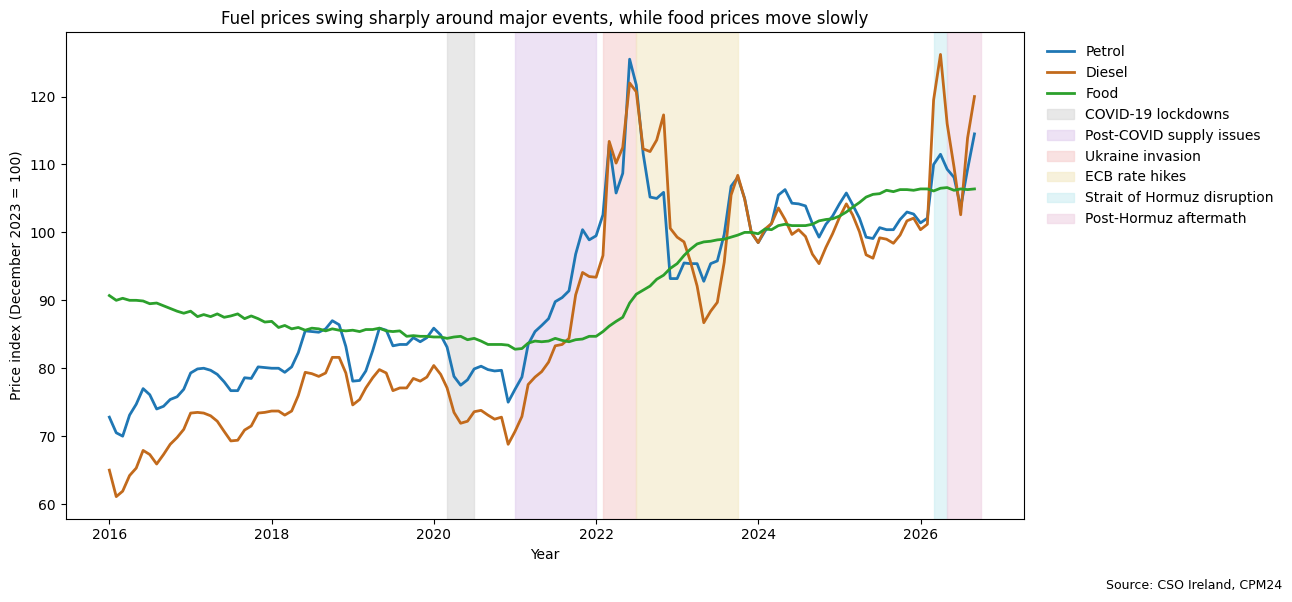

In [4]:
# shading colours for the event periods (pale colours that don't clash with the blue, orange and green lines)
event_colours = ["#d9d9d9", "#e1d0ee", "#f6cfcf", "#f3e9c6", "#cdeef2", "#efd3e4"]

# check there is one shading colour for every event (otherwise some periods would not be shaded)
assert len(event_colours) == len(events)

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(df["Month_DT"], df["Petrol"], color=colours["Petrol"], linewidth=2, label="Petrol")
ax.plot(df["Month_DT"], df["Diesel"], color=colours["Diesel"], linewidth=2, label="Diesel")
ax.plot(df["Month_DT"], df["Food and non-alcoholic beverages"], color=colours["Food"], linewidth=2, label="Food")

# add the event periods
for (event, dates), colour in zip(events.items(), event_colours):
    start = pd.to_datetime(dates[0])
    end = pd.to_datetime(dates[1])
    ax.axvspan(start, end, color=colour, alpha=0.6, label=event)

ax.set_title("Fuel prices swing sharply around major events, while food prices move slowly")
ax.set_xlabel("Year")
ax.set_ylabel("Price index (December 2023 = 100)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)

fig.text(0.99, 0.01, source_text, ha="right", fontsize=9)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig(f"{IMG_DIR}/fuel_and_food_price_trends_with_major_events.png", dpi=300, bbox_inches="tight")
plt.show()

The chart shows sharper fuel price movements during some event periods, while food prices changed more gradually. Fuel prices dropped during the COVID-19 lockdowns and jumped during the Ukraine invasion and the Hormuz disruption. Food prices rose steadily from 2022 to 2023 and stayed almost flat in 2026.

## 4. Monthly Price Changes

We calculate the month-to-month percentage change for petrol, diesel and food indices to compare how much they changed across different periods.

In [5]:
# calculate monthly price changes
df["Petrol_change"] = df["Petrol"].pct_change() * 100
df["Diesel_change"] = df["Diesel"].pct_change() * 100
df["Food_change"] = df["Food and non-alcoholic beverages"].pct_change() * 100

# check the results
df[["Month_DT", "Petrol_change", "Diesel_change", "Food_change"]].head()

,Month_DT,Petrol_change,Diesel_change,Food_change
0,2016-01-01,NaN,NaN,NaN
1,2016-02-01,-3.159341,-6.000000,-0.771775
2,2016-03-01,-0.709220,1.309329,0.333333
3,2016-04-01,4.428571,3.715670,-0.332226
4,2016-05-01,2.188782,1.713396,0.000000


## 5. Event and Normal Periods

First, all months are labelled as "Normal". If a month is within one of the selected event periods, the label is changed to the event name. This groups the months so we can compare normal periods with the event periods. The months after the Hormuz disruption get their own label, so they are not counted as Normal.

In [6]:
# start by marking all months as normal
df["Period"] = "Normal"

# mark the months that fall inside an event period
for event, dates in events.items():
    start = pd.to_datetime(dates[0])
    end = pd.to_datetime(dates[1])

    df.loc[
        (df["Month_DT"] >= start) & (df["Month_DT"] <= end),
        "Period"
    ] = event

# check the result
df[["Month_DT", "Period"]].tail(12)

,Month_DT,Period
117,2025-10-01,Normal
118,2025-11-01,Normal
119,2025-12-01,Normal
120,2026-01-01,Normal
121,2026-02-01,Normal
122,2026-03-01,Strait of Hormuz disruption
123,2026-04-01,Strait of Hormuz disruption
124,2026-05-01,Post-Hormuz aftermath
125,2026-06-01,Post-Hormuz aftermath
126,2026-07-01,Post-Hormuz aftermath


We also check how many months are included in each period, so we know how much data is being compared for each event. The first month (January 2016) has no monthly change, so it is not counted.

Some periods only have 2–5 months, so their results are less reliable. That is why the number of months (n) is shown on the charts.

In [7]:
# order the periods: Normal first, then the events in time order
period_order = ["Normal"] + list(events.keys())

# count the monthly changes in each period
n_changes = df.groupby("Period")["Food_change"].count().loc[period_order]

n_changes

Period
Normal                         85
COVID-19 lockdowns              4
Post-COVID supply issues       12
Ukraine invasion                5
ECB rate hikes                 15
Strait of Hormuz disruption     2
Post-Hormuz aftermath           5
Name: Food_change, dtype: int64

## 6. Average Monthly Changes

We group the monthly changes by period and calculate the average change for petrol, diesel and food. This helps us compare how prices moved during normal and event periods.

In [8]:
# average monthly price change for each period
average_changes = df.groupby("Period")[
    ["Petrol_change", "Diesel_change", "Food_change"]
].mean().round(2).loc[period_order]

average_changes

,Petrol_change,Diesel_change,Food_change
Period,,,
Normal,0.11,0.15,-0.01
COVID-19 lockdowns,-1.98,-2.24,-0.12
Post-COVID supply issues,2.35,2.61,0.13
Ukraine invasion,5.02,5.71,1.13
ECB rate hikes,-0.96,-0.80,0.69
Strait of Hormuz disruption,4.55,11.84,0.05
Post-Hormuz aftermath,0.60,-0.72,-0.02


## 7. Maximum Monthly Changes

We identify the largest monthly change within each period to compare the strongest price movements. We use the absolute value, so a big fall counts the same as a big rise.

In [9]:
# find the largest monthly change in each period (either direction)
max_monthly_change = df.groupby("Period")[
    ["Petrol_change", "Diesel_change", "Food_change"]
].agg(lambda x: x.abs().max()).round(2).loc[period_order]

max_monthly_change

,Petrol_change,Diesel_change,Food_change
Period,,,
Normal,6.13,6.00,1.04
COVID-19 lockdowns,5.17,4.67,0.59
Post-COVID supply issues,6.10,7.58,0.97
Ukraine invasion,15.46,17.39,2.40
ECB rate hikes,11.99,14.24,1.45
Strait of Hormuz disruption,7.74,18.08,0.38
Post-Hormuz aftermath,5.40,11.01,0.38


We compare the maximum monthly changes in each event period with the normal period to see how much higher or lower they were.

In [10]:
# compare the largest monthly changes with the normal period
normal_max_change = max_monthly_change.loc["Normal"]

max_change_comparison = max_monthly_change.subtract(normal_max_change).round(2)

max_change_comparison

,Petrol_change,Diesel_change,Food_change
Period,,,
Normal,0.00,0.00,0.00
COVID-19 lockdowns,-0.96,-1.33,-0.45
Post-COVID supply issues,-0.03,1.58,-0.07
Ukraine invasion,9.33,11.39,1.36
ECB rate hikes,5.86,8.24,0.41
Strait of Hormuz disruption,1.61,12.08,-0.66
Post-Hormuz aftermath,-0.73,5.01,-0.66


The Strait of Hormuz and Ukraine invasion periods had the largest diesel changes, about 12 and 11 percentage points higher than the normal period. The largest food change was 2.4% during the Ukraine invasion. The Strait of Hormuz period only contains two months of data.

## 8. Price Volatility

We calculate the volatility (standard deviation) of the monthly changes in each period to compare how stable or variable the price movements were.

In [11]:
# calculate price volatility for each period
volatility = df.groupby("Period")[
    ["Petrol_change", "Diesel_change", "Food_change"]
].std().round(2).loc[period_order]

volatility

,Petrol_change,Diesel_change,Food_change
Period,,,
Normal,2.05,2.20,0.40
COVID-19 lockdowns,2.54,2.09,0.37
Post-COVID supply issues,2.16,2.41,0.45
Ukraine invasion,8.27,7.67,0.71
ECB rate hikes,4.86,5.80,0.42
Strait of Hormuz disruption,4.51,8.82,0.47
Post-Hormuz aftermath,4.23,8.43,0.22


Here, we compare the volatility in each event period with the normal period to see how much more or less variable the price movements were.

In [12]:
# compare volatility with the normal period
normal_volatility = volatility.loc["Normal"]

volatility_comparison = volatility.subtract(normal_volatility).round(2)

volatility_comparison

,Petrol_change,Diesel_change,Food_change
Period,,,
Normal,0.00,0.00,0.00
COVID-19 lockdowns,0.49,-0.11,-0.03
Post-COVID supply issues,0.11,0.21,0.05
Ukraine invasion,6.22,5.47,0.31
ECB rate hikes,2.81,3.60,0.02
Strait of Hormuz disruption,2.46,6.62,0.07
Post-Hormuz aftermath,2.18,6.23,-0.18


Fuel prices were about 3–4 times more volatile than normal during the Ukraine invasion. Diesel was also very volatile during the Hormuz disruption and the months after it.
Food price volatility stayed much lower than fuel price volatility in every period.

## 9. Visual Comparison

The following charts compare the average monthly change, price volatility and maximum monthly change across the different periods. Each period label shows the number of months (n).

In [13]:
# x-axis labels that show the number of monthly changes in each period
# (long names are wrapped onto two lines so they fit under the bars)
period_labels = [f"{textwrap.fill(period, 16)}\n(n={n_changes[period]})" for period in period_order]


def plot_period_bars(table, title, ylabel, filename):
    """Grouped bar chart of petrol, diesel and food for each period."""
    # give the columns short names so the legend shows Petrol, Diesel and Food
    table = table.rename(columns={
        "Petrol_change": "Petrol",
        "Diesel_change": "Diesel",
        "Food_change": "Food"
    })

    ax = table.plot(
        kind="bar",
        figsize=(12, 6),
        width=0.8,
        color=[colours["Petrol"], colours["Diesel"], colours["Food"]],
        edgecolor="white",
        linewidth=0.8
    )

    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("Period")
    ax.set_ylabel(ylabel)
    ax.set_xticklabels(period_labels, rotation=0, fontsize=9)
    ax.legend(frameon=False)

    plt.figtext(0.99, 0.01, source_text, ha="right", fontsize=9)
    plt.tight_layout(rect=[0, 0.03, 1, 1])
    plt.savefig(f"{IMG_DIR}/{filename}", dpi=300, bbox_inches="tight")
    plt.show()

### Average Monthly Change

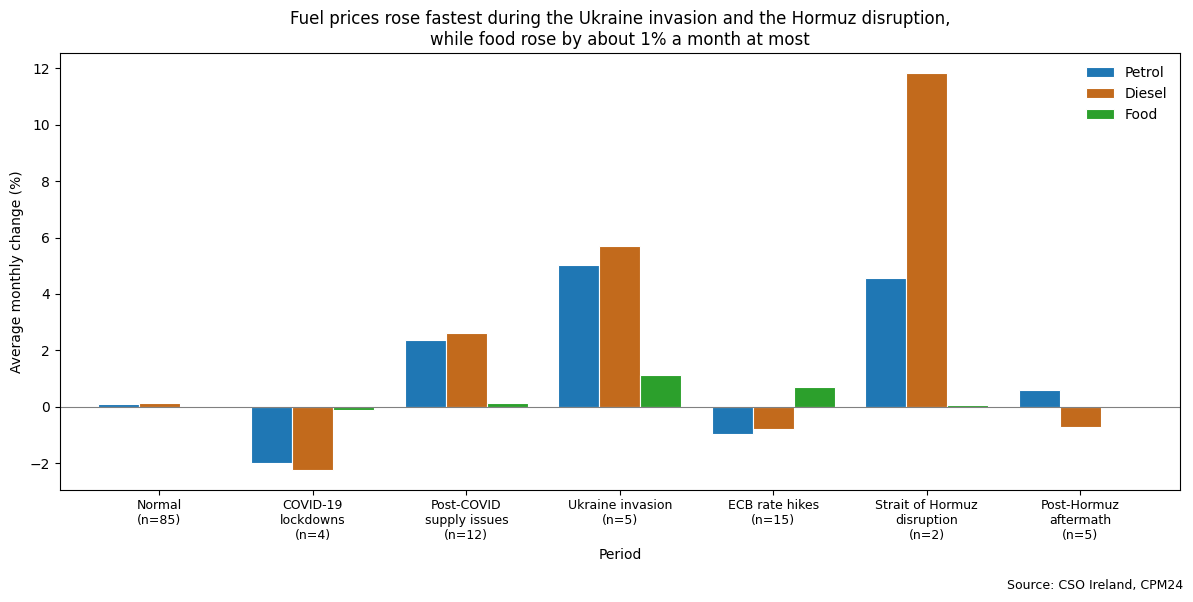

In [14]:
plot_period_bars(
    average_changes,
    "Fuel prices rose fastest during the Ukraine invasion and the Hormuz disruption,\nwhile food rose by about 1% a month at most",
    "Average monthly change (%)",
    "average_monthly_price_change_by_period.png"
)

The chart shows larger average monthly fuel changes during the Ukraine invasion and Strait of Hormuz periods, while food changes were much smaller. Fuel prices fell during the COVID-19 lockdowns. During the ECB rate hikes, food prices still rose by about 0.7% a month while fuel prices were falling.

### Price Volatility
The average monthly change shows the overall direction and size of the changes, while the next chart shows how much the monthly changes varied within each period.

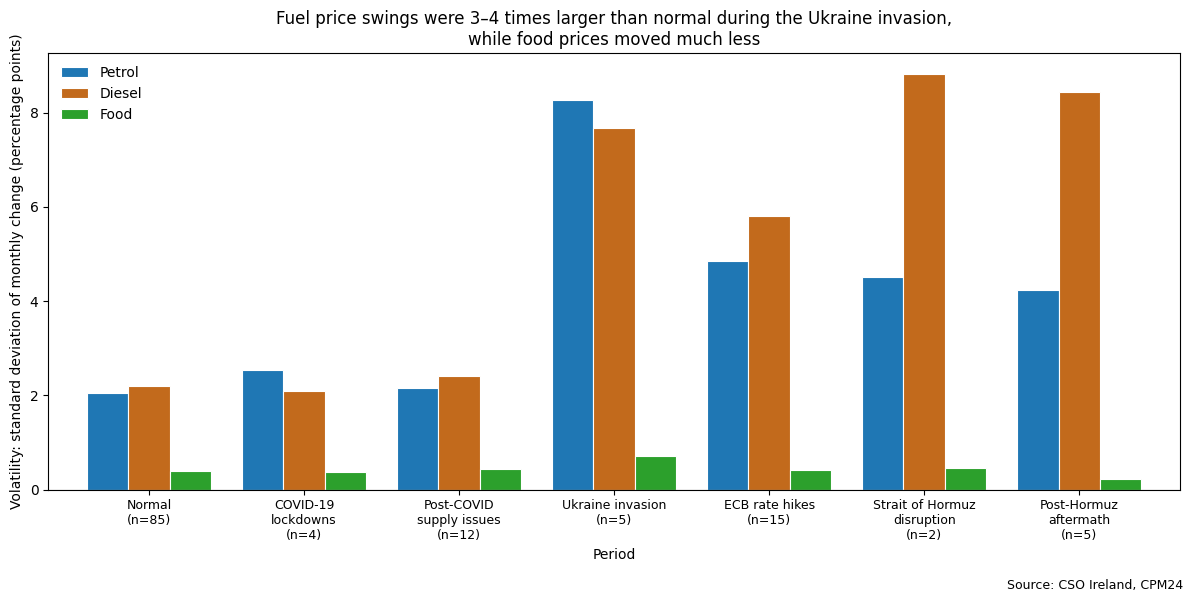

In [15]:
plot_period_bars(
    volatility,
    "Fuel price swings were 3–4 times larger than normal during the Ukraine invasion,\nwhile food prices moved much less",
    "Volatility: standard deviation of monthly change (percentage points)",
    "price_volatility_by_period.png"
)

Fuel prices were more volatile during the Ukraine invasion, ECB rate hikes and Strait of Hormuz periods, while food prices remained more stable.

### Maximum Monthly Change

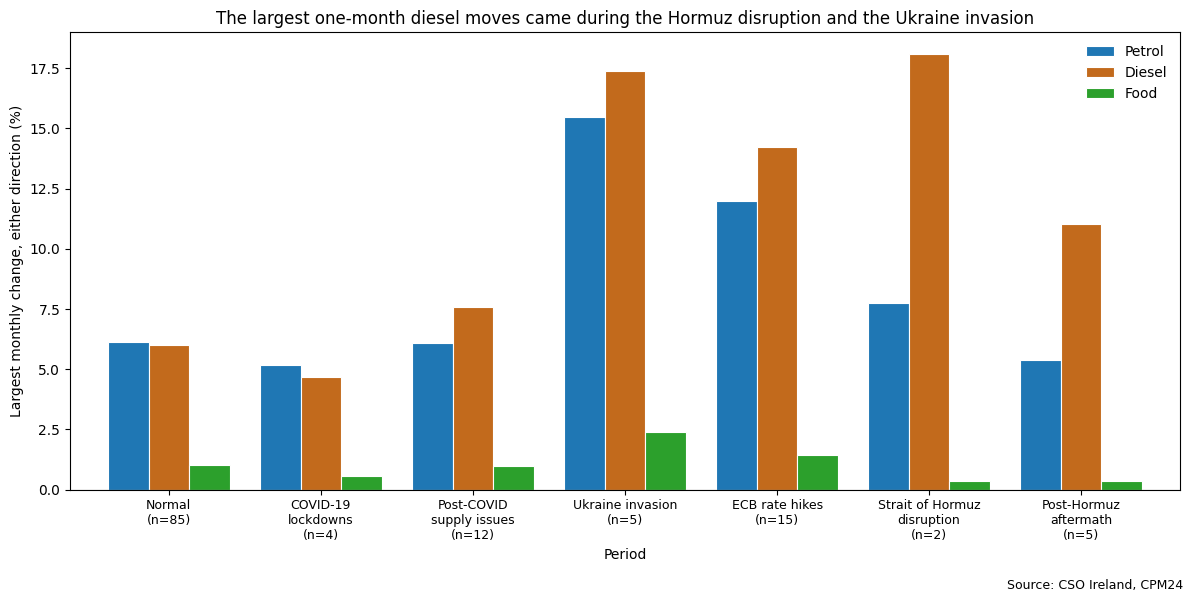

In [16]:
plot_period_bars(
    max_monthly_change,
    "The largest one-month diesel moves came during the Hormuz disruption and the Ukraine invasion",
    "Largest monthly change, either direction (%)",
    "maximum_monthly_price_change_by_period.png"
)

The largest monthly fuel changes occurred during the Ukraine invasion and Strait of Hormuz periods. Some of the large changes were falls, for example diesel dropped by 14.2% in December 2022 during the ECB period. Food prices changed less sharply than petrol and diesel.

## 10. Summary and Limitations

Fuel prices changed much more than food prices during the event periods, especially during the Ukraine invasion and the Strait of Hormuz disruption. Food prices rose most during the Ukraine invasion and the ECB rate hikes. Fuel prices rose sharply during the Ukraine invasion and then fell during the ECB rate hikes, but food prices kept rising.
This could suggest a delay between fuel and food price changes, which is explored in Notebook 05.

Limitations:
- Some periods are very short (2–5 months), so their results are less reliable.
- We chose the event dates ourselves, so different dates would give different results.
- This shows association only, not cause.
- Volatility here is measured as the spread (standard deviation) of monthly changes. Notebook 06 uses the average size of monthly changes, which gives 4–5 times instead of 3–4 times. Both measures tell the same story.